# 03 · Explore landlords: HPD registrations and contacts
**Datasets**
- [Multiple Dwelling Registrations](https://data.cityofnewyork.us/d/tesw-yqqr): every rental building with 3+ apartments must register yearly with HPD. One row per building.
- [Registration Contacts](https://data.cityofnewyork.us/d/feu5-w2e2): the people and companies on each registration (owner, managing agent, officers …).

**Why it matters:** this is how we answer **Q2: does the landlord matter?** We link buildings that share an owner or managing agent into **portfolios**.

**Questions for this notebook**
1. How many buildings are registered, and how do they link to PLUTO?
2. Which kinds of contacts are listed?
3. How messy are owner names, and does normalizing them help?
4. How big are landlord portfolios?

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src import config, housing as H, preprocess as P
from src.plots import save, ACCENT, MUTED

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_colwidth", 80)

pluto = pd.read_parquet(config.CLEAN_PLUTO_FILE, columns=["bbl", "is_residential", "unitsres", "yearbuilt"])
pluto_bbls = set(pluto["bbl"])
residential_bbls = set(pluto.loc[pluto["is_residential"], "bbl"])

## 1. Registrations

In [2]:
reg = H.load("hpd_registrations")
reg["bbl"] = H.bbl_from_parts(reg["boroid"], reg["block"], reg["lot"])
print(f"{len(reg):,} registrations | {reg['buildingid'].nunique():,} buildings | {reg['bbl'].nunique():,} BBLs")
H.overview(reg)

187,127 registrations | 187,122 buildings | 176,715 BBLs


,missing_%,distinct,example
registrationid,0.00,187042,139143
buildingid,0.00,187122,1065
boroid,0.00,5,1
boro,0.00,5,MANHATTAN
housenumber,0.00,19627,235
lowhousenumber,0.00,19719,235
highhousenumber,0.00,19813,245
streetname,0.00,5357,EAST 92 STREET
streetcode,0.00,5499,10110
zip,0.00,186,10128


In [3]:
reg["registrationenddate"] = pd.to_datetime(reg["registrationenddate"].astype(str), errors="coerce")
active = reg["registrationenddate"] >= pd.Timestamp.today()
print(f"Active registrations (end date in the future): {active.mean():.1%}")
print(f"Registered BBLs found in PLUTO: {H.coverage(reg['bbl'], pluto_bbls):.1%}")
res_units = pluto.set_index("bbl")["unitsres"]
reg_units = res_units[res_units.index.isin(set(reg["bbl"].dropna()))].sum()
print(f"Apartments in registered buildings: {reg_units:,.0f} of {res_units.sum():,.0f} "
      f"({reg_units / res_units.sum():.0%} of NYC's apartments)")

Active registrations (end date in the future): 65.8%


Registered BBLs found in PLUTO: 99.9%


Apartments in registered buildings: 2,586,012 of 3,741,982 (69% of NYC's apartments)


## 2. Contacts: who is listed?

In [4]:
con = H.load("hpd_contacts")
print(f"{len(con):,} contacts on {con['registrationid'].nunique():,} registrations")
display(H.overview(con))
con["type"].value_counts().to_frame("contacts").T

744,753 contacts on 183,939 registrations


,missing_%,distinct,example
registrationcontactid,0.00,743302,13914303
registrationid,0.00,183939,139143
type,0.00,9,CorporateOwner
contactdescription,0.20,510,CO-OP
corporationname,73.80,112058,RUPPERT HOUSING CO INC
title,83.90,3630,PRESIDENT
firstname,15.70,55349,SABREEN
middleinitial,86.50,69,H
lastname,15.80,76970,SPEARS
businesshousenumber,21.50,21705,9


type,SiteManager,Agent,HeadOfficer,CorporateOwner,Officer,IndividualOwner,JointOwner,Shareholder,Lessee
contacts,155841,148387,120552,114462,65309,47234,44873,41835,6260


In [5]:
# Contacts per registration, by type
per_reg = con.groupby(["registrationid", "type"]).size().unstack(fill_value=0)
(per_reg > 0).mean().mul(100).round(1).sort_values(ascending=False).to_frame("% of registrations listing this type").T

type,SiteManager,Agent,HeadOfficer,CorporateOwner,Officer,IndividualOwner,Shareholder,JointOwner,Lessee
% of registrations listing this type,84.70,80.60,65.50,62.20,34.70,25.70,15.40,12.10,3.40


## 3. Names are messy, and normalizing helps
Corporate owners are often LLCs, one per building, so the *same* landlord appears under many names. We look at three keys:
- **Corporation name**, normalized: case, punctuation and LLC/INC suffixes removed.
- **Managing agent**: the person or company that actually runs the building.
- **Business address**: LLCs owned by one landlord often share an office address.

In [6]:
con["corp_norm"] = H.normalize_name(con["corporationname"])
con["person"] = H.normalize_name(con["firstname"].astype("string").fillna("") + " " + con["lastname"].astype("string").fillna(""))
con["biz_addr"] = H.normalize_address(con["businesshousenumber"], con["businessstreetname"], con["businesszip"])

examples = con.dropna(subset=["corp_norm"]).groupby("corp_norm")["corporationname"].agg(["nunique", lambda s: list(s.unique()[:4])])
examples.columns = ["raw spellings", "examples"]
examples.sort_values("raw spellings", ascending=False).head(8)

,raw spellings,examples
corp_norm,,
MAXWELL KATES,19,"['MAXWELL KATES INC.' 'MAXWELL-KATES INC.' 'MAXWELL-KATES, INC.' 'MAXWELL-K..."
HALSTEAD MANAGEMENT,15,['HALSTEAD MANAGEMENT CO.' 'HALSTEAD MANAGEMENT CO' 'halstead management co...
JOHN B LOVETT,14,['JOHN B LOVETT' 'JOHN B LOVETT & ASSOC' 'JOHN B. LOVETT' 'JOHN B LOVETt']
NHE MANAGEMENT,11,"['N.H.E MANAGEMENT ASSOC., LLC' 'N H E MANAGEMENT ASSOC LLC' 'NHE MANAGEMEN..."
WALLACK MANAGEMENT,10,"['WALLACK MANAGEMENT COMPANY INC.' 'WALLACK MANAGEMENT COMPANY, INC.' 'WALL..."
ROBERT E HILL,10,"['ROBERT E. HILL, INC.' 'ROBERT E HILL, INC.' 'ROBERT E. HILL INC.' 'ROBERT..."
CENTURY MANAGEMENT SERVICES,10,['CENTURY MANAGEMENT SERVICES INC' 'CENTURY MANAGEMENT SERVICES' 'CENTURY M...
PRESTIGE MANAGEMENT,10,['PRESTIGE MANAGEMENT INC' 'Prestige Management Inc.' 'PRESTIGE MANAGEMENT ...


In [7]:
print(f"Distinct raw corporation names: {con['corporationname'].nunique():,} → normalized: {con['corp_norm'].nunique():,}")

Distinct raw corporation names: 112,058 → normalized: 102,278


## 4. How big are portfolios?

In [8]:
links = con.merge(reg[["registrationid", "bbl"]], on="registrationid", how="left")

def portfolio_sizes(df, key, types):
    d = df[df["type"].isin(types)].dropna(subset=[key, "bbl"])
    return d.groupby(key)["bbl"].nunique().sort_values(ascending=False)

owners = portfolio_sizes(links, "corp_norm", ["CorporateOwner"])
agents_corp = portfolio_sizes(links, "corp_norm", ["Agent"])
agents_person = portfolio_sizes(links, "person", ["Agent"])
offices = portfolio_sizes(links, "biz_addr", ["CorporateOwner", "HeadOfficer"])

summary = pd.DataFrame({
    name: {"groups": len(s), "buildings covered": int(s.sum()), "median size": s.median(),
           "groups with 10+ buildings": int((s >= 10).sum()), "largest": int(s.max())}
    for name, s in {"corporate owner name": owners, "agent company": agents_corp,
                    "agent person": agents_person, "owner business address": offices}.items()}).T
summary

,groups,buildings covered,median size,groups with 10+ buildings,largest
corporate owner name,"89,336.00","105,222.00",1.00,207.00,248.00
agent company,"30,548.00","68,635.00",1.00,849.00,526.00
agent person,"63,668.00","138,422.00",1.00,"1,856.00",363.00
owner business address,"67,862.00","137,641.00",1.00,"1,650.00",443.00


,buildings managed (agent company)
corp_norm,
FIRSTSERVICE RESIDENTIAL,526
FREESTONE PROPERTY GROUP,435
AKAM,360
DOUGLAS ELLIMAN PROPERTY MANAGEMENT,303
CONCORD MANAGEMENT OF NY,293
REM RESIDENTIAL,263
SHINDA MANAGEMENT,249
WAVECREST MGMT GROUP,241
ANDREWS ORGANIZATION,232


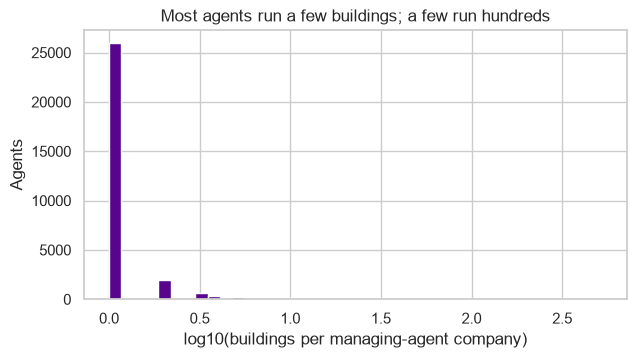

In [9]:
display(agents_corp.head(15).to_frame("buildings managed (agent company)"))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.log10(agents_corp), bins=40, color=ACCENT)
ax.set(xlabel="log10(buildings per managing-agent company)", ylabel="Agents",
       title="Most agents run a few buildings; a few run hundreds")
save(fig, "rent03a_portfolio_sizes")

## 5. Takeaways
- Only buildings with **3+ apartments** register, but they hold most of NYC's apartments (see the share above), and that's where most renters live.
- **Owner LLC names** split one landlord into many "owners". The **managing agent** and the **owner's business address** group buildings much better.
- **Landlord key for the project:** the managing-agent company (or person when no company is listed), with the business address as a backup link. In cleaning we merge these into one *portfolio id* using a small graph: buildings connected by a shared agent or shared office.

→ Next: **04_explore_bedbugs_evictions.ipynb**